In [1]:

import pandas as pd
from google.colab import files

uploaded = files.upload()

file_name = next(iter(uploaded))
df = pd.read_csv(file_name)

print("Dataset Shape:", df.shape)
print("\nColumn Names:")
print(df.columns.tolist())

print("\nFirst 5 Rows:")
display(df.head())


Saving customer_churn_raw_v2 (1).csv to customer_churn_raw_v2 (1) (1).csv
Dataset Shape: (605, 13)

Column Names:
['CustomerID', 'Age', 'Region', 'TenureMonths', 'SubscriptionType', 'MonthlyChargesINR', 'TotalChargesINR', 'ContractType', 'SupportTickets', 'LatePayments', 'PaymentMethod', 'AutoPay', 'Churn']

First 5 Rows:


,CustomerID,Age,Region,TenureMonths,SubscriptionType,MonthlyChargesINR,TotalChargesINR,ContractType,SupportTickets,LatePayments,PaymentMethod,AutoPay,Churn
0,CUST-100001,20,NaN,9,Pro,13097.76,unknown,Month-to-Month,1,2,Card,No,Yes
1,CUST-100002,55,Central,52,Pro,1101.18,57334.22,One Year,0,0,Card,Yes,No
2,CUST-100003,40,Central,67,Standard,692.66,44554.47,Month-to-Month,6,2,UPI,No,Yes
3,CUST-100004,53,South,48,Pro,1156.49,53956.12,One Year,2,2,Card,Yes,No
4,CUST-100005,21,West,24,Standard,754.16,18191.59,Month-to-Month,0,1,Card,Yes,No


In [2]:

# Check customer churn values
print("Churn column values:")
print(df["Churn"].value_counts(dropna=False))

print("\nColumn names:")
print(df.columns.tolist())


Churn column values:
Churn
No     355
Yes    250
Name: count, dtype: int64

Column names:
['CustomerID', 'Age', 'Region', 'TenureMonths', 'SubscriptionType', 'MonthlyChargesINR', 'TotalChargesINR', 'ContractType', 'SupportTickets', 'LatePayments', 'PaymentMethod', 'AutoPay', 'Churn']


In [3]:

total_customers = len(df)

churned_customers = (df["Churn"] == "Yes").sum()

churn_rate = (churned_customers / total_customers) * 100

print("Total Customers:", total_customers)
print("Churned Customers:", churned_customers)
print("Churn Rate:", round(churn_rate, 2), "%")


Total Customers: 605
Churned Customers: 250
Churn Rate: 41.32 %


In [4]:

# Calculate estimated customer lifetime revenue
df["CLV"] = df["MonthlyChargesINR"] * df["TenureMonths"]

# Average CLV of all customers
average_clv = df["CLV"].mean()

# Average CLV of churned customers
churned_clv = df.loc[df["Churn"] == "Yes", "CLV"].mean()

print("Average CLV of all customers:", round(average_clv, 2))
print("Average CLV of churned customers:", round(churned_clv, 2))


Average CLV of all customers: 30364.95
Average CLV of churned customers: 30041.43


In [6]:

# Calculate monthly recurring revenue lost from churned customers
churned_df = df[df["Churn"] == "Yes"]

mrr_loss = churned_df["MonthlyChargesINR"].sum()

print("Churned Customers:", len(churned_df))
print("Estimated Monthly Revenue Loss: ₹", round(mrr_loss, 2))


Churned Customers: 250
Estimated Monthly Revenue Loss: ₹ 242346.38


In [7]:

# Churn rate by Contract Type

contract_churn = pd.crosstab(
    df["ContractType"],
    df["Churn"],
    normalize="index"
) * 100

print("Churn Rate by Contract Type:")
print(contract_churn.round(2))


Churn Rate by Contract Type:
Churn              No    Yes
ContractType                
Month-to-Month  39.94  60.06
One Year        79.64  20.36
Two Year        79.17  20.83


In [8]:

# Churn rate by customer tenure

df["TenureGroup"] = pd.cut(
    df["TenureMonths"],
    bins=[0, 12, 24, 48, 100],
    labels=["0-12 Months", "13-24 Months",
            "25-48 Months", "49+ Months"],
    include_lowest=True
)

tenure_churn = pd.crosstab(
    df["TenureGroup"],
    df["Churn"],
    normalize="index"
) * 100

print("Churn Rate by Tenure:")
print(tenure_churn.round(2))


Churn Rate by Tenure:
Churn            No    Yes
TenureGroup               
0-12 Months   45.28  54.72
13-24 Months  54.55  45.45
25-48 Months  61.90  38.10
49+ Months    65.00  35.00


In [9]:

# Churn rate by payment method

payment_churn = pd.crosstab(
    df["PaymentMethod"],
    df["Churn"],
    normalize="index"
) * 100

print("Churn Rate by Payment Method:")
print(payment_churn.round(2))


Churn Rate by Payment Method:
Churn             No    Yes
PaymentMethod              
Card           62.42  37.58
Net Banking    63.12  36.88
UPI            54.55  45.45
Wallet         54.88  45.12


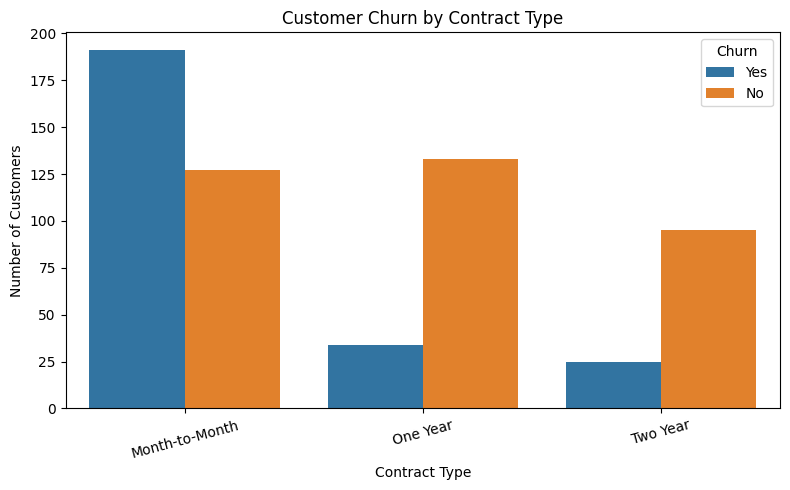

In [10]:

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="ContractType",
    hue="Churn"
)

plt.title("Customer Churn by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Number of Customers")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


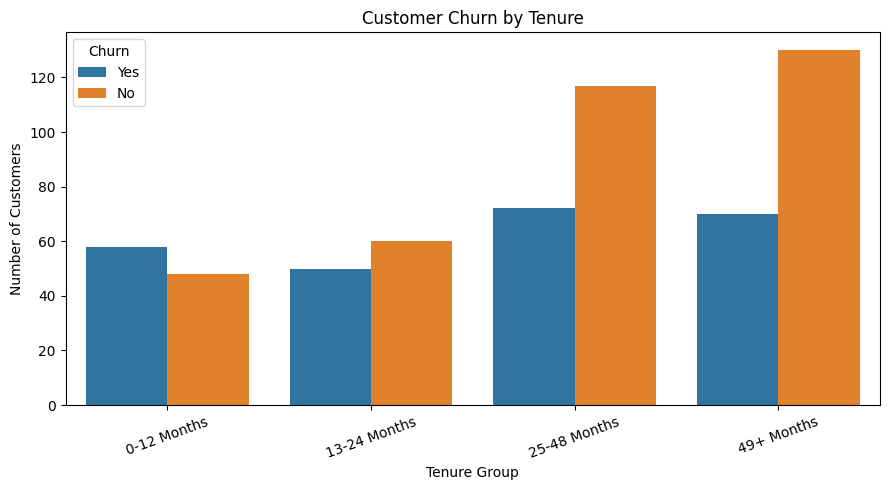

In [11]:

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x="TenureGroup",
    hue="Churn"
)

plt.title("Customer Churn by Tenure")
plt.xlabel("Tenure Group")
plt.ylabel("Number of Customers")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


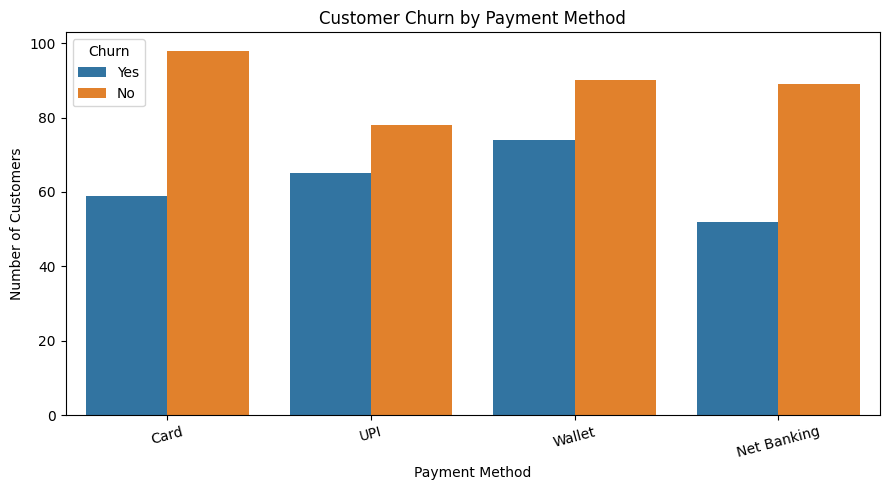

In [12]:

plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x="PaymentMethod",
    hue="Churn"
)

plt.title("Customer Churn by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Number of Customers")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


In [14]:

print(df.columns.tolist())


['CustomerID', 'Age', 'Region', 'TenureMonths', 'SubscriptionType', 'MonthlyChargesINR', 'TotalChargesINR', 'ContractType', 'SupportTickets', 'LatePayments', 'PaymentMethod', 'AutoPay', 'Churn', 'CLV', 'TenureGroup']


In [16]:

print("Available columns:")
for col in df.columns:
    print(repr(col))


Available columns:
'CustomerID'
'Age'
'Region'
'TenureMonths'
'SubscriptionType'
'MonthlyChargesINR'
'TotalChargesINR'
'ContractType'
'SupportTickets'
'LatePayments'
'PaymentMethod'
'AutoPay'
'Churn'
'CLV'
'TenureGroup'


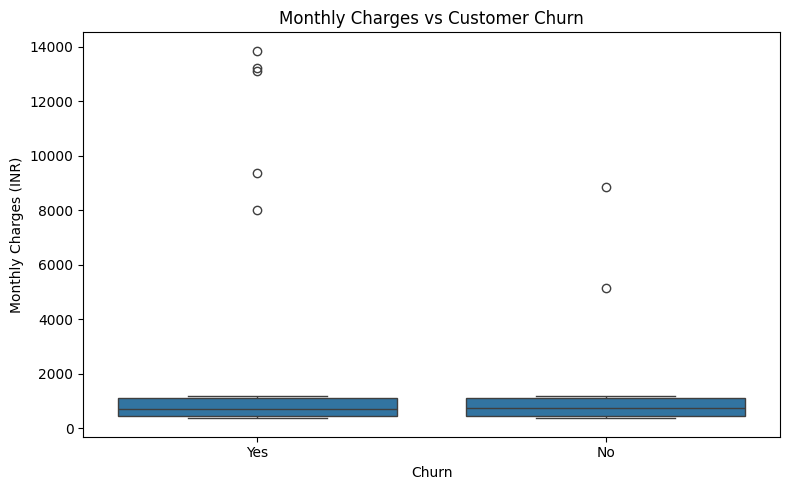

In [18]:

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Churn",
    y="MonthlyChargesINR"
)

plt.title("Monthly Charges vs Customer Churn")
plt.xlabel("Churn")
plt.ylabel("Monthly Charges (INR)")
plt.tight_layout()
plt.show()


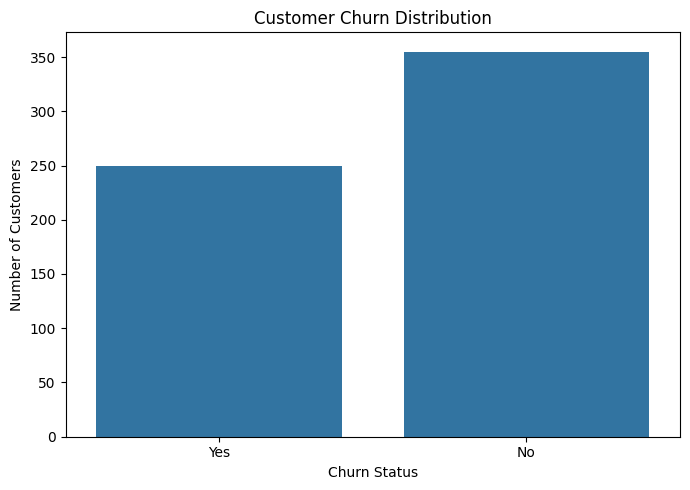

In [19]:

plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="Churn")

plt.title("Customer Churn Distribution")
plt.xlabel("Churn Status")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()


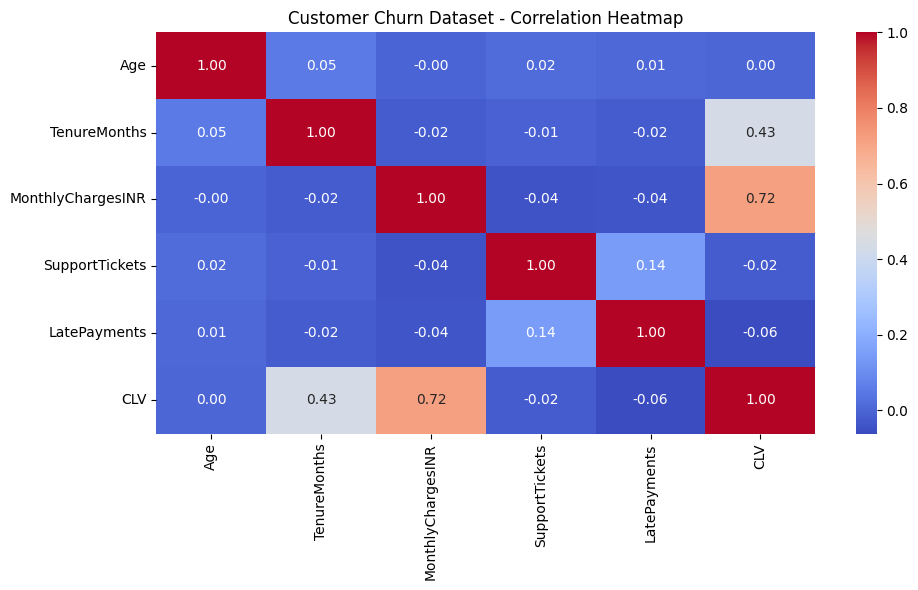

In [20]:

# Select numerical columns only
numeric_df = df.select_dtypes(include="number")

# Create correlation heatmap
plt.figure(figsize=(10, 6))

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Customer Churn Dataset - Correlation Heatmap")
plt.tight_layout()
plt.show()


In [21]:

# 1. Total customers
total_customers = len(df)

# 2. Churned customers
churned_customers = (df["Churn"] == "Yes").sum()

# 3. Churn rate
churn_rate = (churned_customers / total_customers) * 100

# 4. Estimated monthly revenue loss
monthly_revenue_loss = df.loc[
    df["Churn"] == "Yes", "MonthlyChargesINR"
].sum()

print("CUSTOMER CHURN ANALYSIS - FINAL RESULTS")
print("---------------------------------------")
print("Total Customers:", total_customers)
print("Churned Customers:", churned_customers)
print(f"Churn Rate: {churn_rate:.2f}%")
print(f"Estimated Monthly Revenue at Risk: ₹{monthly_revenue_loss:,.2f}")


CUSTOMER CHURN ANALYSIS - FINAL RESULTS
---------------------------------------
Total Customers: 605
Churned Customers: 250
Churn Rate: 41.32%
Estimated Monthly Revenue at Risk: ₹242,346.38


# Customer Churn Analysis

## 1. Project Objective
The objective of this project is to analyze customer churn, identify patterns in customer behavior, and understand the factors that may influence customers to leave a service.

## 2. Tools and Technologies
- Python
- Google Colab
- Pandas and NumPy
- Matplotlib and Seaborn

## 3. Analysis Performed
- Analyzed customer churn distribution.
- Compared churn across different contract types.
- Studied churn based on customer tenure.
- Analyzed churn across payment methods.
- Visualized monthly charges using a box plot.
- Generated a correlation heatmap for numerical variables.
- Estimated monthly revenue at risk from churned customers.

## 4. Key Findings
- The dataset contains 605 customer records.
- 250 customers are marked as churned and 355 as non-churned.
- The overall churn rate is approximately 41.32%.
- Month-to-month contract customers show a higher churn rate than customers with longer-term contracts.
- Customers with shorter tenure show a higher churn rate than customers with longer tenure.

## 5. Business Recommendations
- Improve customer support and follow up with customers who may leave.
- Offer suitable benefits to encourage long-term contracts.
- Identify new customers who may need additional support.
- Review customer feedback and payment-related concerns.
- Monitor churn rate and monthly revenue at risk regularly.

## 6. Conclusion
This project uses Python-based data analysis and visualization to understand customer churn patterns. The findings can help businesses identify customer groups that may be more likely to leave and develop suitable retention strategies. The analysis shows patterns and associations; it does not prove that a particular factor directly causes churn.